In [ ]:
import requests
import xml.etree.ElementTree as ET
import pandas as pd
import geopandas as gpd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import re
from scipy.stats import pearsonr
import matplotlib as mpl

# Load the EcoBase data





*   If you want to use the EcoBase data used in our study, download the file "df.csv", upload it to Google Colab, and run the code below. The data in "df.csv" was retrieved on May 30, 2026.

In [ ]:
df = pd.read_csv("data/df.csv")

*   If you want to use the latest EcoBase data instead of the dataset used in our study, uncomment and run the following code.

In [ ]:
"""
# Get the list of ecosystem models from EcoBase
url = "http://sirs.agrocampus-ouest.fr/EcoBase/php/webser/soap-client_3.php"
response = requests.get(url)
response.raise_for_status()

# Parse XML response
root = ET.fromstring(response.text)

# Convert XML to DataFrame
data = []
for model in root.findall(".//model"):
    record = {child.tag: child.text for child in model}
    data.append(record)

df = pd.DataFrame(data)
df = df[df["dissemination_allow"] == "true"] # Filter models with dissemination permission
"""

'\n# Get the list of ecosystem models from EcoBase\nurl = "http://sirs.agrocampus-ouest.fr/EcoBase/php/webser/soap-client_3.php"\nresponse = requests.get(url)\nresponse.raise_for_status()\n\n# Parse XML response\nroot = ET.fromstring(response.text)\n\n# Convert XML to DataFrame\ndata = []\nfor model in root.findall(".//model"):\n    record = {child.tag: child.text for child in model}\n    data.append(record)\n\ndf = pd.DataFrame(data)\ndf = df[df["dissemination_allow"] == "true"] # Filter models with dissemination permission\n'

# Reconstruct parameters in the generalized Lotka–Volterra equation from EcoBase

*   If you want to use the EcoBase data used in our study, download the file "Ecopath_list.pkl", upload it to Google Colab, and run the code below. The data in "Ecopath_list.pkl" was retrieved on May 30, 2026.
"Ecopath_list.pkl" contains biomass $B_i$, production/biomass ratio $(P/B)_i$, consumption/biomass ratio $(Q/B)_i$, and the proportion of species $i$ in the diet of species $j$, $(DC_{ij})$, for each data.

In [ ]:
Ecopath_list = pd.read_pickle("data/Ecopath_list.pkl")

*   If you want to use the latest EcoBase data instead of the dataset used in our study, uncomment and run the following code. This may take a few minutes.

In [ ]:
"""
def Ecopath(i):
  model_number=model_numbers[i]

  # Get each model from EcoBase
  url_model = f"http://sirs.agrocampus-ouest.fr/EcoBase/php/webser/soap-client.php?no_model={model_number}"
  response_model = requests.get(url_model)
  response_model.raise_for_status()
  root_model = ET.fromstring(response_model.text)

  # Convert XML to DataFrame
  data_model = []
  for group in root_model.findall(".//group"):
      record = {child.tag: child.text for child in group}
      data_model.append(record)

  df_model = pd.DataFrame(data_model)

  group_seq_list=df_model["group_seq"].tolist()

  biomass_list=[float(x) for x in df_model["biomass"].tolist()]
  pb_list=[float(x) for x in df_model["pb"].tolist()]
  qb_list=[float(x) for x in df_model["qb"].tolist()]

  n=len(group_seq_list)
  Int=np.zeros((n, n))

  for group in root_model.findall(".//group"):
    predator_seq = group.find("group_seq").text
    predator_num=group_seq_list.index(predator_seq)
    diet=group.findall(".//diet")
    for d in diet:
      prey_seq=d.find("prey_seq").text
      prey_num=group_seq_list.index(prey_seq)
      proportion=float(d.find("proportion").text)
      Int[prey_num, predator_num]=proportion

  return biomass_list, pb_list, qb_list, Int


model_numbers = df["model_number"].tolist()
Ecopath_list = [Ecopath(i) for i in range(len(model_numbers))]
"""

'\ndef Ecopath(i):\n  model_number=model_numbers[i]\n\n  # Get each model from EcoBase\n  url_model = f"http://sirs.agrocampus-ouest.fr/EcoBase/php/webser/soap-client.php?no_model={model_number}"\n  response_model = requests.get(url_model)\n  response_model.raise_for_status()\n  root_model = ET.fromstring(response_model.text)\n\n  # Convert XML to DataFrame\n  data_model = []\n  for group in root_model.findall(".//group"):\n      record = {child.tag: child.text for child in group}\n      data_model.append(record)\n\n  df_model = pd.DataFrame(data_model)\n\n  group_seq_list=df_model["group_seq"].tolist()\n\n  biomass_list=[float(x) for x in df_model["biomass"].tolist()]\n  pb_list=[float(x) for x in df_model["pb"].tolist()]\n  qb_list=[float(x) for x in df_model["qb"].tolist()]\n\n  n=len(group_seq_list)\n  Int=np.zeros((n, n))\n\n  for group in root_model.findall(".//group"):\n    predator_seq = group.find("group_seq").text\n    predator_num=group_seq_list.index(predator_seq)\n    diet

Construct the biomass matrix $X=\mathrm{diag}(\bar{x}_1,\ldots, \bar{x}_N)$ and interaction matrix $A$.

In [ ]:
def X_A(i):
  """Construct the graph G representing interspecies interaction, biomass matrix X, and interaction matrix A"""
  (biomass_list, pb_list, qb_list, Int) = Ecopath_list[i]

  biomass_list = np.array(biomass_list)
  pb_list      = np.array(pb_list)
  qb_list      = np.array(qb_list)

  # Remove the species with invalid entries (-9999)
  mask = (biomass_list != -9999) & (pb_list != -9999) & (qb_list != -9999)

  biomass_list = biomass_list[mask]
  pb_list      = pb_list[mask]
  qb_list     = qb_list[mask]
  Int     = Int[mask][:, mask]

  X=np.diag(biomass_list)

  n=len(biomass_list)

  A=np.zeros((n, n))

  for i in range(n):
    for j in range(n):
      A[i, j]+= -qb_list[j]*Int[i, j]/biomass_list[i]
      A[j, i]+= pb_list[j]*Int[i, j]/biomass_list[i]

  np.fill_diagonal(A, 0.0)

  return X, A

In [ ]:
X_A_list = [X_A(i) for i in range(len(Ecopath_list))]

In [ ]:
N_list = [X.shape[0] for (X, A) in X_A_list]

# Plot the EcoBase data on a global map

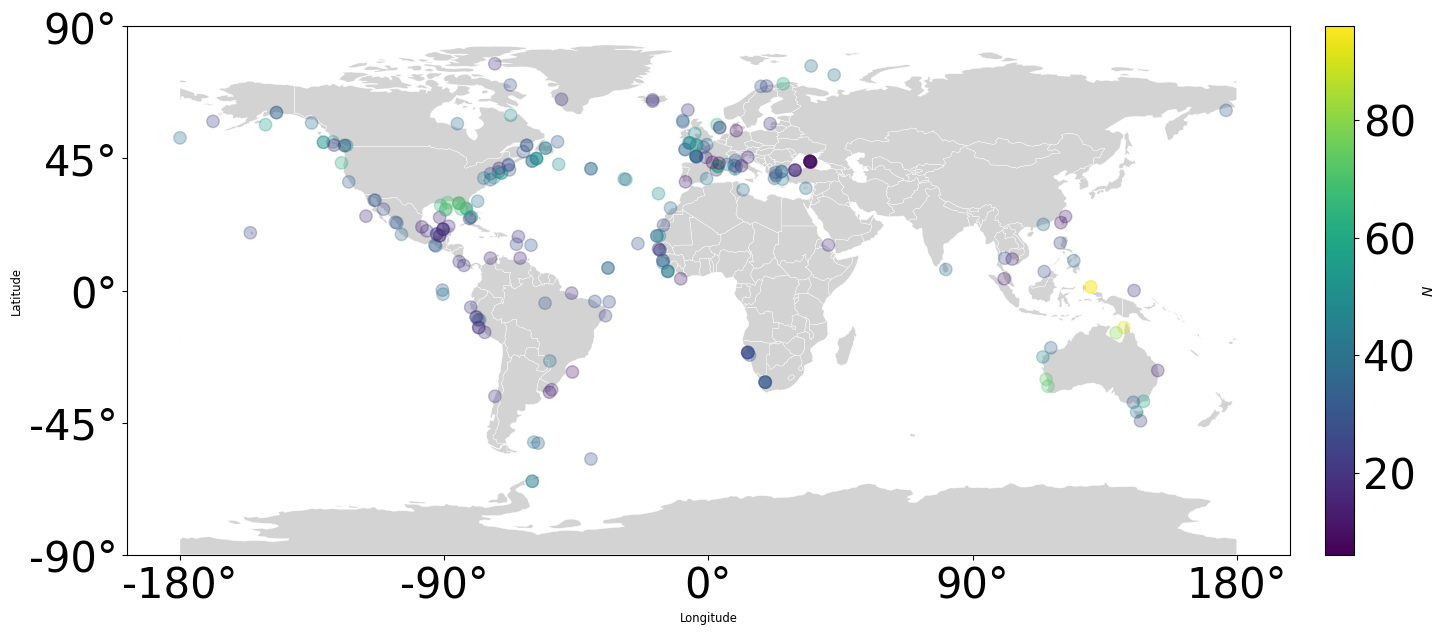

In [ ]:
N_values = np.asarray(N_list, dtype=float)

if N_values.ndim != 1 or len(df) != N_values.size or N_values.size == 0:
    raise ValueError(
        "df and N_list must have the same length and must not be empty."
    )


def box_center(box):
    """BOX の経緯度中点を計算する。日付変更線をまたぐ範囲にも対応。"""

    values = re.findall(
        r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?",
        str(box)
    )

    if len(values) != 4:
        raise ValueError(f"Invalid geographic_extent: {box!r}")

    west, south, east, north = map(float, values)

    # 例：170° から -170° の範囲を、170° から 190° として扱う。
    if east < west:
        east += 360

    lon = ((west + east) / 2 + 180) % 360 - 180
    lat = (south + north) / 2

    return lon, lat


lon, lat = np.array([
    box_center(box) for box in df["geographic_extent"]
]).T


world = gpd.read_file(
    "https://naciscdn.org/naturalearth/110m/cultural/"
    "ne_110m_admin_0_countries.zip"
).to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(15, 10))

world.plot(
    ax=ax,
    color="lightgray",
    edgecolor="white",
    linewidth=0.3
)


sc = ax.scatter(
    lon,
    lat,
    c=N_values,
    cmap="viridis",
    s=80,
    alpha=0.3,
    zorder=5
)


x_ticks = np.arange(-180, 181, 90)
y_ticks = np.arange(-90, 91, 45)

ax.set_xticks(x_ticks)
ax.set_yticks(y_ticks)

ax.set_xticklabels([f"{value}°" for value in x_ticks])
ax.set_yticklabels([f"{value}°" for value in y_ticks])

ax.tick_params(axis="both", labelsize=30)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")


lon_margin = 18

ax.set_xlim(
    -180 - lon_margin,
    180 + lon_margin
)
ax.set_ylim(-90, 90)

ax.set_aspect("equal", adjustable="box")


sm = mpl.cm.ScalarMappable(
    norm=sc.norm,
    cmap=sc.cmap
)
sm.set_array([])

cax = ax.inset_axes([1.03, 0, 0.025, 1])

cbar = fig.colorbar(
    sm,
    cax=cax,
    alpha=1.0
)

cbar.set_label(r"$N$")
cbar.ax.tick_params(labelsize=30)

fig.savefig(
    "global_map_color.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

# Validation of our results using EcoBase

In [ ]:
def compute_a1_b2(B):
    B = np.array(B)

    B_sym = (B + B.T)/2
    B_skew = (B - B.T)/2

    np.fill_diagonal(B_sym, 0)
    np.fill_diagonal(B_skew, 0)

    a_F = np.sqrt(np.sum(B_sym**2))
    a_inf = np.max(np.sum(np.abs(B_sym), axis=1))

    b_F = np.sqrt(np.sum(B_skew**2))
    b_inf = np.max(np.sum(np.abs(B_skew), axis=1))

    a1 = min(a_F, a_inf)
    b2 = min(b_F, b_inf)

    return a1, b2

In [ ]:
alpha_list = []
nu_list=[]

omega_list = []
a1_list = []
b2_list = []

omega_tilde_list = []
a1_tilde_list = []
b2_tilde_list = []

omega_hat_list = []
a1_hat_list = []
b2_hat_list = []

for (X, A) in X_A_list:
  M = X@A

  eigvals = np.linalg.eigvals(M)
  alpha = np.max(eigvals.real)
  alpha_list.append(alpha)
  nu = np.max(eigvals.imag)
  nu_list.append(nu)

  M_sym = (M+M.T)/2
  eigvals_M_sym = np.linalg.eigvals(M_sym)
  omega = np.max(eigvals_M_sym.real)
  omega_list.append(omega)
  a1, b2 = compute_a1_b2(M)
  a1_list.append(a1)
  b2_list.append(b2)

  M_tilde = A@X
  M_tilde_sym = (M_tilde+M_tilde.T)/2
  eigvals_M_tilde_sym = np.linalg.eigvals(M_tilde_sym)
  omega_tilde = np.max(eigvals_M_tilde_sym.real)
  omega_tilde_list.append(omega_tilde)
  a1_tilde, b2_tilde = compute_a1_b2(M_tilde)
  a1_tilde_list.append(a1_tilde)
  b2_tilde_list.append(b2_tilde)

  M_hat = np.sqrt(X)@A@np.sqrt(X)
  M_hat_sym = (M_hat+M_hat.T)/2
  eigvals_M_hat_sym = np.linalg.eigvals(M_hat_sym)
  omega_hat = np.max(eigvals_M_hat_sym.real)
  omega_hat_list.append(omega_hat)
  a1_hat, b2_hat = compute_a1_b2(M_hat)
  a1_hat_list.append(a1_hat)
  b2_hat_list.append(b2_hat)

In [ ]:
def plot_with_color(list1, list2, title, x_label, y_label,
                    dot=False, shade_y_greater=False):

    list1 = np.array(list1)
    list2 = np.array(list2)

    fig, ax = plt.subplots(figsize=(7, 7))

    sc = ax.scatter(
        list1,
        list2,
        c=N_list,
        cmap='viridis',
        alpha=1.0,
        edgecolors='white',
        s=60
    )

    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(r"Number of species")

    cbar.locator = MaxNLocator(5)
    cbar.update_ticks()

    cbar.ax.tick_params(labelsize=30)

    xy_min = min(list1.min(), list2.min())
    xy_max = max(list1.max(), list2.max())

    margin = 0.05 * (xy_max - xy_min)

    plot_min = xy_min - margin
    plot_max = xy_max + margin

    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)

    x_vals = np.linspace(plot_min, plot_max, 500)

    if dot:
        ax.plot(
            x_vals,
            x_vals,
            color='crimson',
            linewidth=3,
            linestyle=':'
        )
    else:
        ax.plot(
            x_vals,
            x_vals,
            color='crimson',
            linewidth=1
        )

    if shade_y_greater:
        ax.fill_between(
            x_vals,
            x_vals,
            plot_max,
            color='gray',
            alpha=0.25
        )

    ax.xaxis.set_major_locator(MaxNLocator(3))
    ax.yaxis.set_major_locator(MaxNLocator(3))

    ax.tick_params(
        axis='both',
        labelsize=25
    )

    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    ax.set_aspect('equal', adjustable='box')
    ax.set_box_aspect(1)

    plt.savefig(
        title + ".svg",
        format='svg',
        bbox_inches='tight'
    )

    plt.show()

Plots of $\alpha$ vs $a_1$, $\omega$ vs $a_1$, and $\nu$ vs $b_2$ with Pearson correlation coefficient $r$ and p-value for testing non-correlation $p$

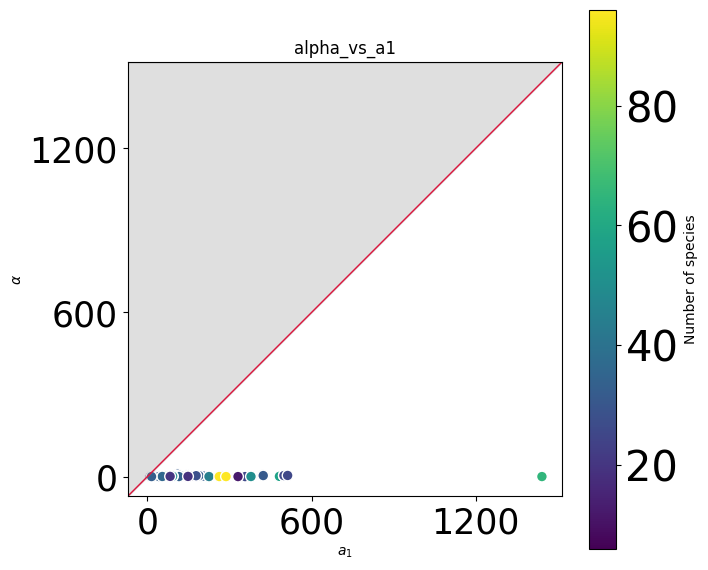

r = 0.3255738243881359
p = 3.95634068469869e-07


In [ ]:
plot_with_color(a1_list, alpha_list, title = "alpha_vs_a1", x_label = r"$a_1$", y_label = r"$\alpha$", shade_y_greater=True)

r, p_value = pearsonr(a1_list, alpha_list)
print("r =", r)
print("p =", p_value)

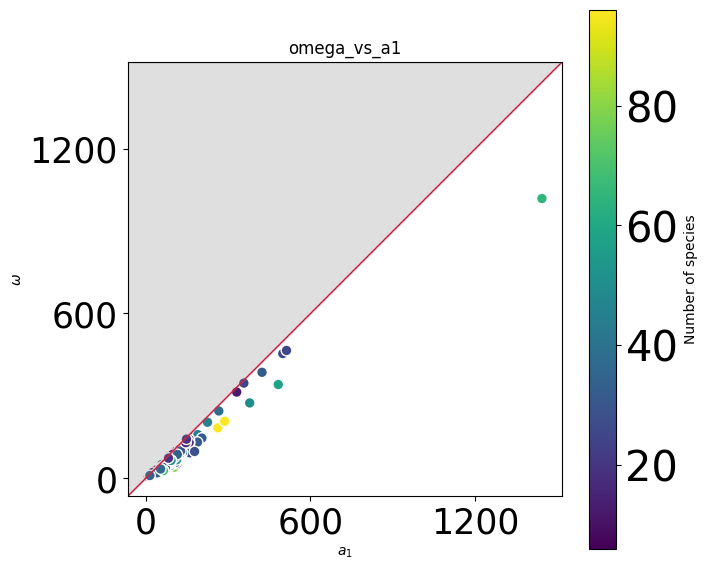

r = 0.9843535126737283
p = 2.048901966625918e-175


In [ ]:
plot_with_color(a1_list, omega_list, title = "omega_vs_a1", x_label = r"$a_1$", y_label = r"$\omega$", shade_y_greater=True)

r, p_value = pearsonr(a1_list, omega_list)
print("r =", r)
print("p =", p_value)

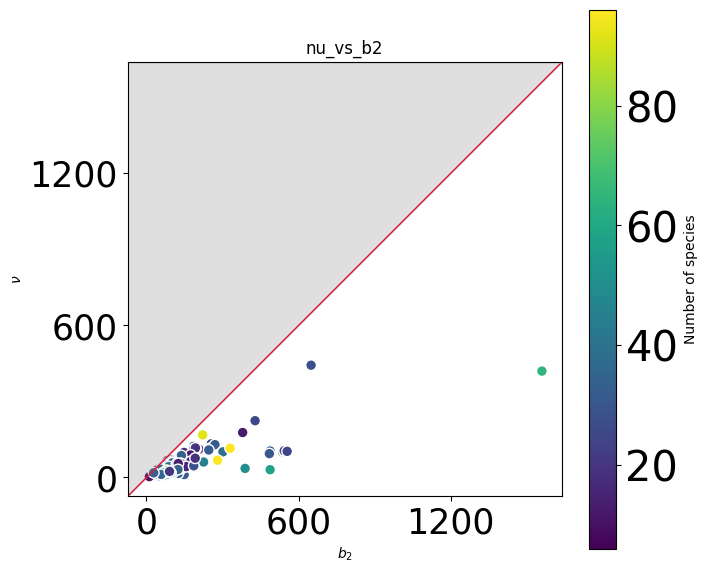

r = 0.8149240959613567
p = 2.1013817347737704e-56


In [ ]:
plot_with_color(b2_list, nu_list, title = "nu_vs_b2", x_label = r"$b_2$", y_label = r"$\nu$", shade_y_greater=True)

r, p_value = pearsonr(b2_list, nu_list)
print("r =", r)
print("p =", p_value)

Plots of $\alpha$ vs $\widetilde{a}_1$, $\widetilde{\omega}$ vs $\widetilde{a}_1$, and $\nu$ vs $\widetilde{b}_2$ with Pearson correlation coefficient $r$ and p-value for testing non-correlation $p$

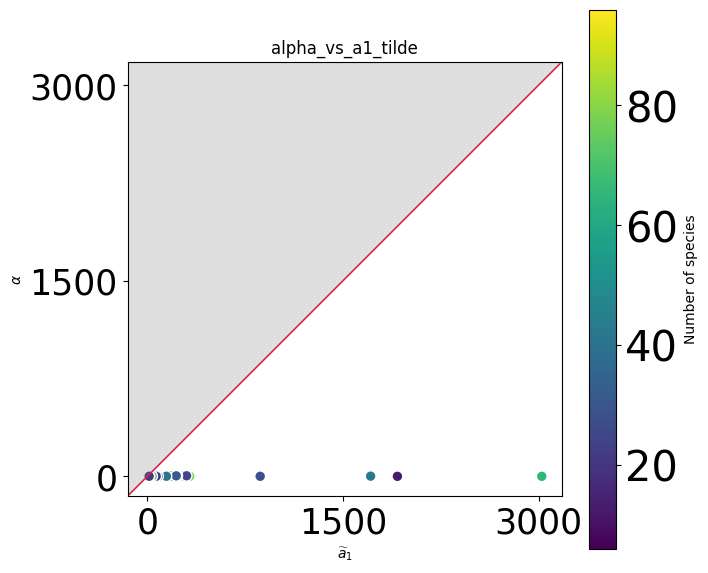

r = 0.058436484873856484
p = 0.37560252619885093


In [ ]:
plot_with_color(a1_tilde_list, alpha_list, title = "alpha_vs_a1_tilde", x_label = r"$\widetilde{a}_1$", y_label = r"$\alpha$", shade_y_greater=True)

r, p_value = pearsonr(alpha_list, a1_tilde_list)
print("r =", r)
print("p =", p_value)

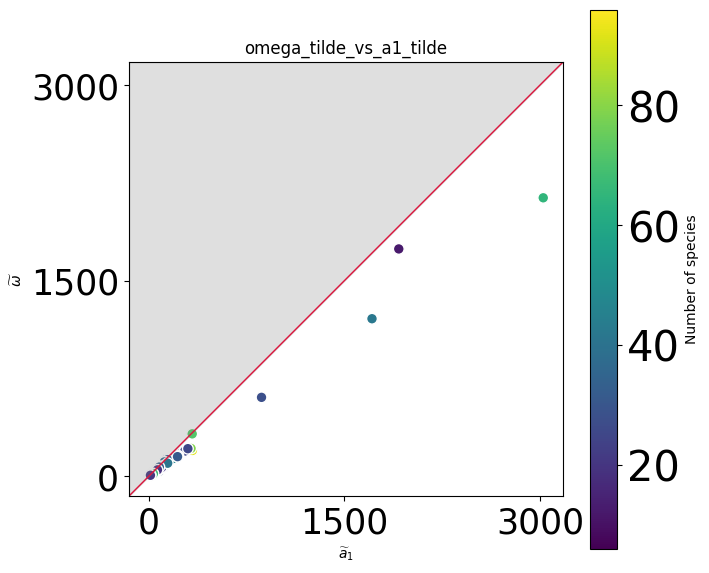

r = 0.9927368299427399
p = 1.5488197992173043e-213


In [ ]:
plot_with_color(a1_tilde_list, omega_tilde_list, title = "omega_tilde_vs_a1_tilde", x_label = r"$\widetilde{a}_1$", y_label = r"$\widetilde{\omega}$", shade_y_greater=True)

r, p_value = pearsonr(a1_tilde_list, omega_tilde_list)
print("r =", r)
print("p =", p_value)

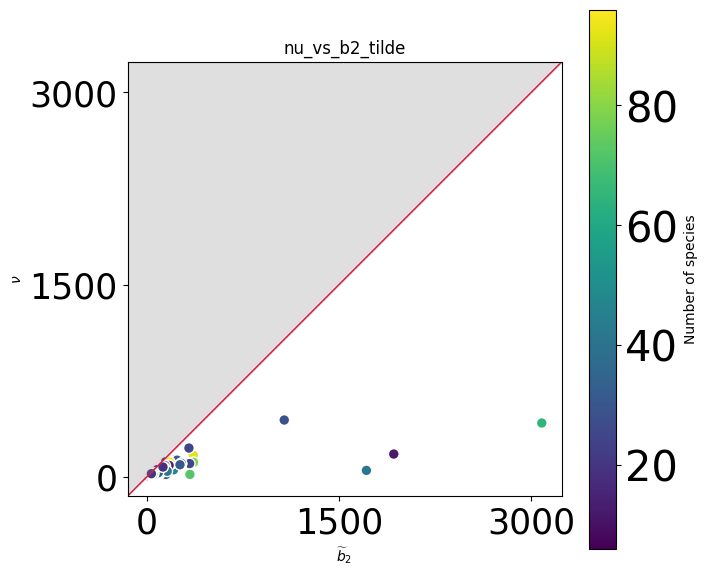

r = 0.7163082538269322
p = 8.30949048811558e-38


In [ ]:
plot_with_color(b2_tilde_list, nu_list, title = "nu_vs_b2_tilde", x_label = r"$\widetilde{b}_2$", y_label = r"$\nu$", shade_y_greater=True)

r, p_value = pearsonr(b2_tilde_list, nu_list)
print("r =", r)
print("p =", p_value)

Plots of $\alpha$ vs $\widehat{a}_1$, $\widehat{\omega}$ vs $\widehat{a}_1$, and $\nu$ vs $\widehat{b}_2$ with Pearson correlation coefficient $r$ and p-value for testing non-correlation $p$

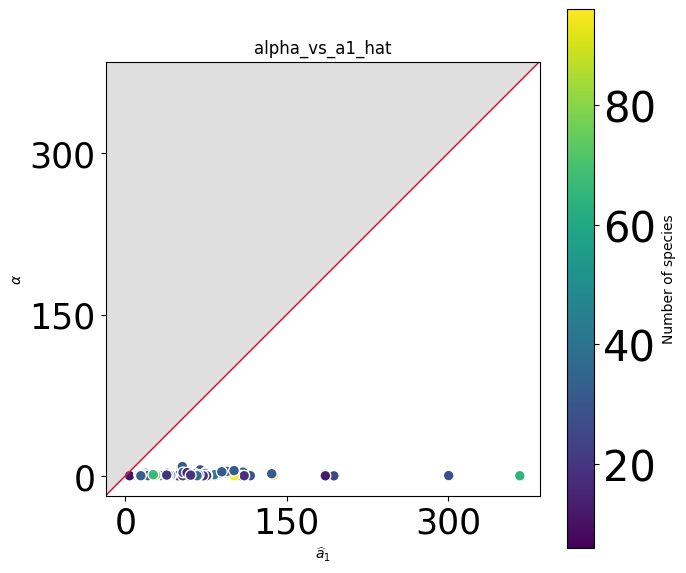

r = 0.22537698410451001
p = 0.0005423725148138564


In [ ]:
plot_with_color(a1_hat_list, alpha_list, title = "alpha_vs_a1_hat", x_label = r"$\widehat{a}_1$", y_label = r"$\alpha$", shade_y_greater=True)

r, p_value = pearsonr(alpha_list, a1_hat_list)
print("r =", r)
print("p =", p_value)

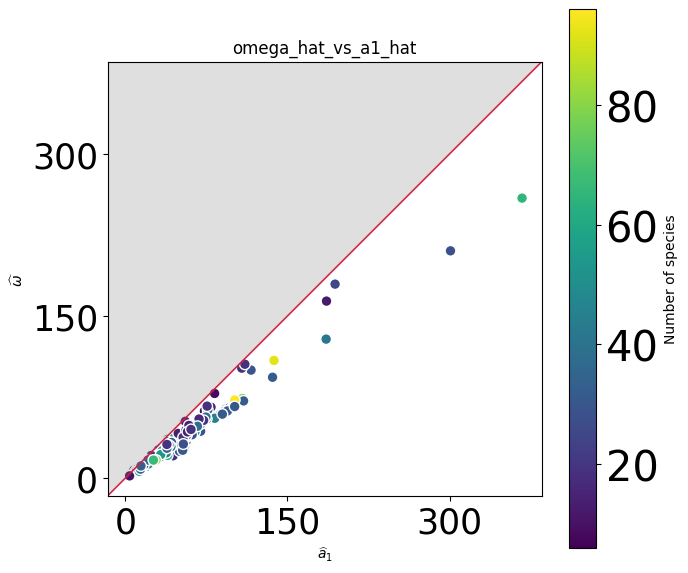

r = 0.9837051572104314
p = 2.105308809207654e-173


In [ ]:
plot_with_color(a1_hat_list, omega_hat_list, title = "omega_hat_vs_a1_hat", x_label = r"$\widehat{a}_1$", y_label = r"$\widehat{\omega}$", shade_y_greater=True)

r, p_value = pearsonr(a1_hat_list, omega_hat_list)
print("r =", r)
print("p =", p_value)

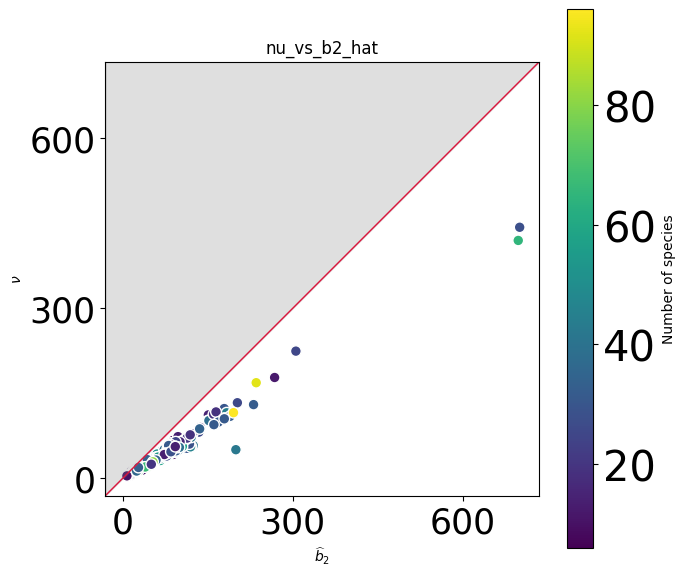

r = 0.9866418017961992
p = 2.9590383390338355e-183


In [ ]:
plot_with_color(b2_hat_list, nu_list, title = "nu_vs_b2_hat", x_label = r"$\widehat{b}_2$", y_label = r"$\nu$", shade_y_greater=True)

r, p_value = pearsonr(b2_hat_list, nu_list)
print("r =", r)
print("p =", p_value)

# Validation of random matrix theory predictions using EcoBase

In [ ]:
alpha_RMT_without_mean_list = []
omega_RMT_without_mean_list = []
nu_RMT_without_mean_list = []

alpha_RMT_with_mean_list = []
omega_RMT_with_mean_list = []
nu_RMT_with_mean_list = []


for (X, A) in X_A_list:

    M = X @ A
    N = M.shape[0]

    off_diag = M[~np.eye(N, dtype=bool)]

    i, j = np.tril_indices(N, k=-1)

    M_lower = M[i, j]
    M_upper = M[j, i]

    connected_pair_mask = (
        (M_lower != 0)
        |
        (M_upper != 0)
    )

    num_pairs = np.count_nonzero(connected_pair_mask)
    total_pairs = len(i)

    C = num_pairs / total_pairs

    off_diag_connected = np.concatenate([
        M_lower[connected_pair_mask],
        M_upper[connected_pair_mask]
    ])

    mean = np.mean(off_diag_connected)
    var = np.var(off_diag_connected)
    rho = (np.mean(M_lower[connected_pair_mask] * M_upper[connected_pair_mask]) - mean**2) / var

    mean_all = np.mean(off_diag)
    var_all = np.var(off_diag)
    rho_all = (np.mean(M_lower * M_upper) - mean_all**2) / var_all


    alpha_RMT_without_mean = (
        (1 + rho)
        * np.sqrt(N * C * var)
    )

    omega_RMT_without_mean = np.sqrt(
        2 * (1 + rho) * N * C * var
    )

    nu_RMT_without_mean = (
        (1 - rho)
        * np.sqrt(N * C * var)
    )


    criterion_1 = (N - 1) * mean_all

    criterion_2 = (
        np.sqrt(N * var_all) * (1 + rho_all)
        - mean_all
    )

    criterion_3 = (
        np.sqrt(
            2 * N * var_all * (1 + rho_all)
        )
        - mean_all
    )

    alpha_RMT_with_mean = max(
        criterion_1,
        criterion_2
    )

    omega_RMT_with_mean = max(
        criterion_1,
        criterion_3
    )

    nu_RMT_with_mean = (
        (1 - rho_all)
        * np.sqrt(N * var_all)
    )


    alpha_RMT_without_mean_list.append(
        alpha_RMT_without_mean
    )

    omega_RMT_without_mean_list.append(
        omega_RMT_without_mean
    )

    nu_RMT_without_mean_list.append(
        nu_RMT_without_mean
    )

    alpha_RMT_with_mean_list.append(
        alpha_RMT_with_mean
    )

    omega_RMT_with_mean_list.append(
        omega_RMT_with_mean
    )

    nu_RMT_with_mean_list.append(
        nu_RMT_with_mean
    )

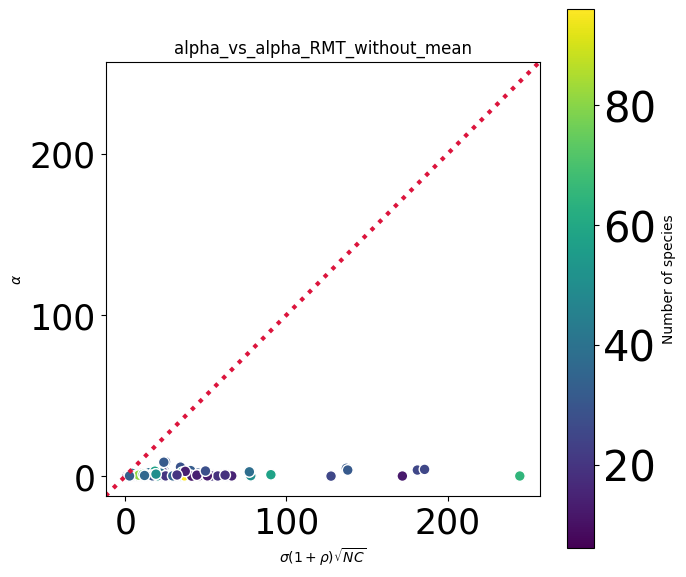

r = 0.38468339096865173
p = 1.3395693542510817e-09


In [ ]:
plot_with_color(alpha_RMT_without_mean_list, alpha_list, title = "alpha_vs_alpha_RMT_without_mean", x_label = r"$\sigma(1+\rho)\sqrt{NC}$", y_label = r"$\alpha$", dot=True)

r, p_value = pearsonr(alpha_RMT_without_mean_list, alpha_list)
print("r =", r)
print("p =", p_value)

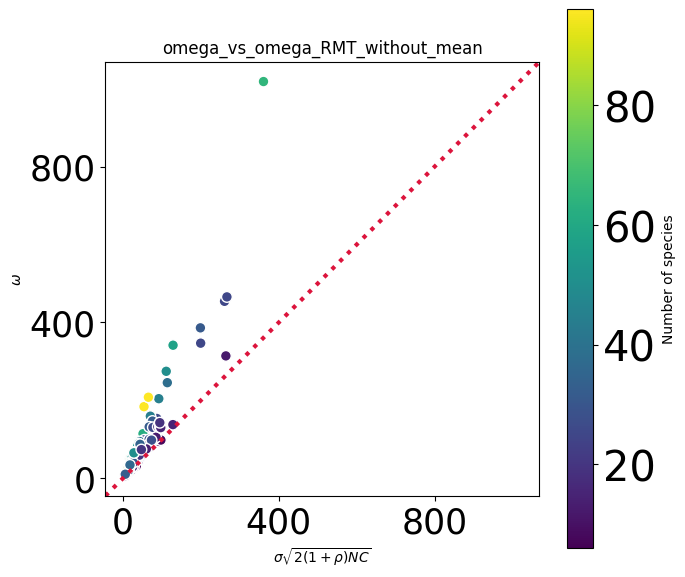

r = 0.9486738861990738
p = 5.651937495658182e-117


In [ ]:
plot_with_color(omega_RMT_without_mean_list, omega_list, title = "omega_vs_omega_RMT_without_mean", x_label = r"$\sigma\sqrt{2(1+\rho)NC}$", y_label = r"$\omega$", dot=True)

r, p_value = pearsonr(omega_RMT_without_mean_list, omega_list)
print("r =", r)
print("p =", p_value)

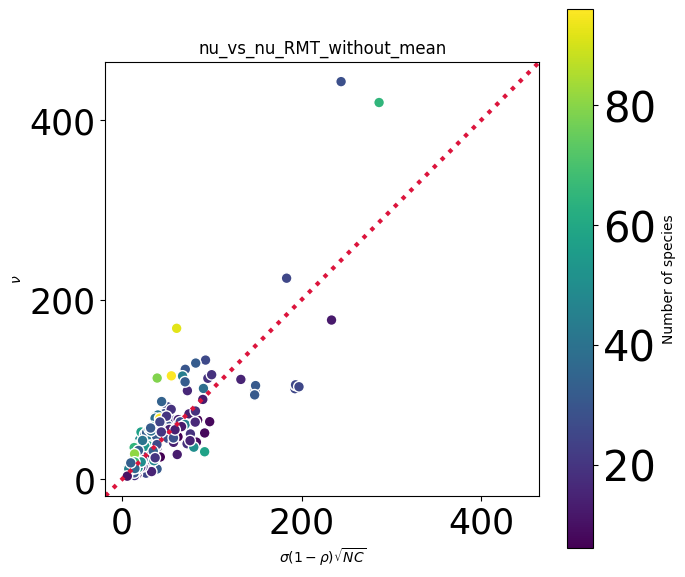

r = 0.8183354242365384
p = 3.0573330860606065e-57


In [ ]:
plot_with_color(nu_RMT_without_mean_list, nu_list, title = "nu_vs_nu_RMT_without_mean", x_label = r"$\sigma(1-\rho)\sqrt{NC}$", y_label = r"$\nu$", dot=True)

r, p_value = pearsonr(nu_RMT_without_mean_list, nu_list)
print("r =", r)
print("p =", p_value)

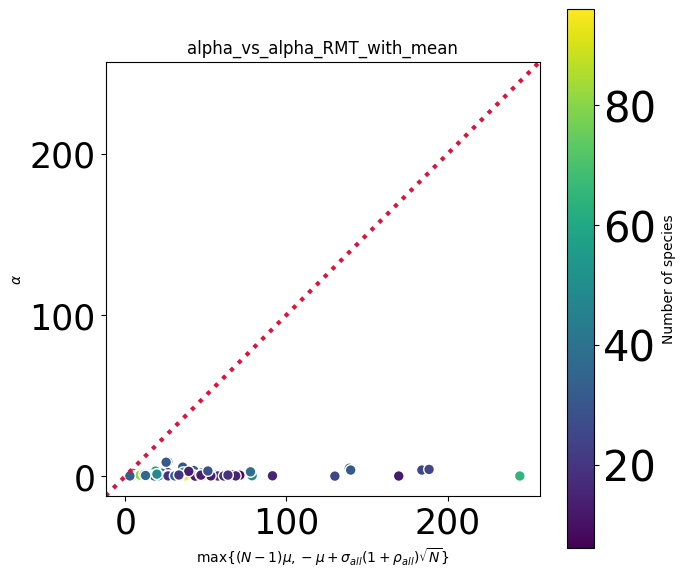

r = 0.3829767054003436
p = 1.6052222536798396e-09


In [ ]:
plot_with_color(alpha_RMT_with_mean_list, alpha_list, title = "alpha_vs_alpha_RMT_with_mean", x_label = r"$\max\{(N-1)\mu, -\mu+\sigma_{all}(1+\rho_{all})\sqrt{N}\}$", y_label = r"$\alpha$", dot=True)

r, p_value = pearsonr(alpha_RMT_with_mean_list, alpha_list)
print("r =", r)
print("p =", p_value)

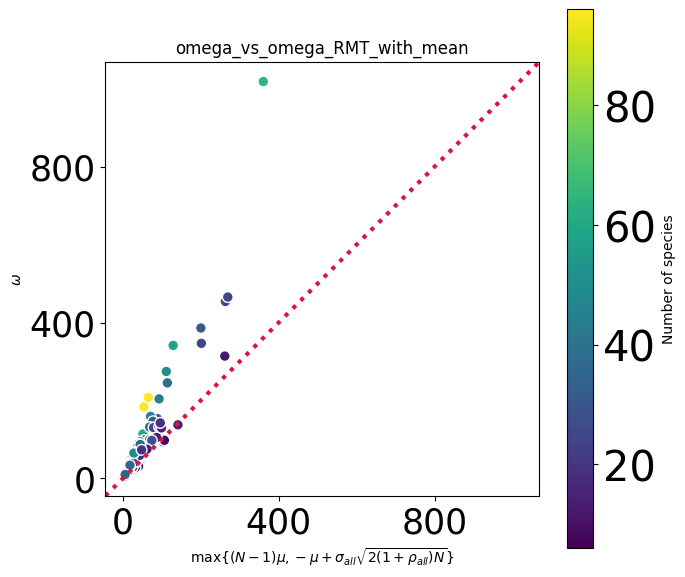

r = 0.9441534790792908
p = 7.143331627406605e-113


In [ ]:
plot_with_color(omega_RMT_with_mean_list, omega_list, title = "omega_vs_omega_RMT_with_mean", x_label = r"$\max\{(N-1)\mu, -\mu+\sigma_{all}\sqrt{2(1+\rho_{all})N}\}$", y_label = r"$\omega$", dot=True)

r, p_value = pearsonr(omega_RMT_with_mean_list, omega_list)
print("r =", r)
print("p =", p_value)

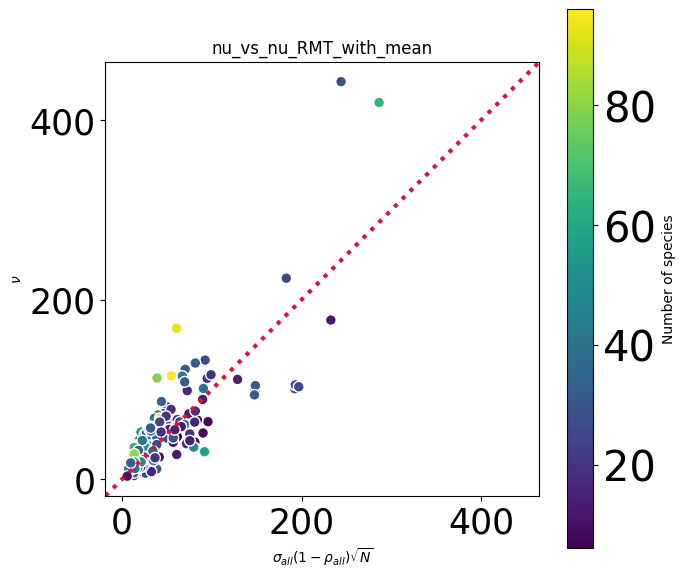

r = 0.8193778639201672
p = 1.6826918059205746e-57


In [ ]:
plot_with_color(nu_RMT_with_mean_list, nu_list, title = "nu_vs_nu_RMT_with_mean", x_label = r"$\sigma_{all}(1-\rho_{all})\sqrt{N}$", y_label = r"$\nu$", dot=True)

r, p_value = pearsonr(nu_RMT_with_mean_list, nu_list)
print("r =", r)
print("p =", p_value)

# Histogram


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_ratio_histogram(
    x_list,
    y_list,
    bins=30,
    color='#2D5CA8',
    x_label=r'$y/x$',
    ax_size=(7, 6),
    filename=None
):

    x = np.asarray(x_list, dtype=float)
    y = np.asarray(y_list, dtype=float)

    if len(x) != len(y):
        raise ValueError(
            "x_list and y_list must have the same length."
        )

    mask = (
        (x != 0)
        & np.isfinite(x)
        & np.isfinite(y)
    )

    ratio = y[mask] / x[mask]

    if len(ratio) == 0:
        raise ValueError(
            "No valid data remain."
        )

    mean_ratio = np.mean(ratio)
    std_ratio = np.std(ratio)

    print(f"Mean = {mean_ratio:.6f}")
    print(f"Standard deviation = {std_ratio:.6f}")

    ax_width, ax_height = ax_size

    left = 1.2
    right = 0.3
    bottom = 1.0
    top = 0.3

    fig_width = left + ax_width + right
    fig_height = bottom + ax_height + top

    fig = plt.figure(
        figsize=(fig_width, fig_height)
    )

    ax = fig.add_axes([
        left / fig_width,
        bottom / fig_height,
        ax_width / fig_width,
        ax_height / fig_height
    ])


    weights = np.ones(len(ratio)) / len(ratio)

    counts, bin_edges, patches = ax.hist(
        ratio,
        bins=bins,
        weights=weights,
        color=color,
        edgecolor='none',
        alpha=0.8
    )


    ax.axvline(
        x=1,
        color='black',
        linestyle=':',
        linewidth=8,
        zorder=3
    )


    x_min = min(bin_edges[0], 1)
    x_max = max(bin_edges[-1], 1)

    margin = 0.05 * (x_max - x_min)

    ax.set_xlim(
        x_min - margin,
        x_max + margin
    )


    ax.set_xlabel(
        x_label,
        fontsize=20
    )

    ax.set_ylabel(
        'Fraction',
        fontsize=20
    )


    ax.tick_params(
        axis='both',
        labelsize=30
    )


    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=3)
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=3)
    )


    xticks = list(ax.get_xticks())

    if not np.any(np.isclose(xticks, 1)):
        xticks.append(1)

    xticks = np.array(sorted(xticks))

    current_xlim = ax.get_xlim()

    xticks = xticks[
        (xticks >= current_xlim[0])
        & (xticks <= current_xlim[1])
    ]

    ax.set_xticks(xticks)


    if filename is not None:
        plt.savefig(
            filename,
            format='svg'
        )


    plt.show()


    return ratio, mean_ratio, std_ratio

Mean = 0.009240
Standard deviation = 0.011979


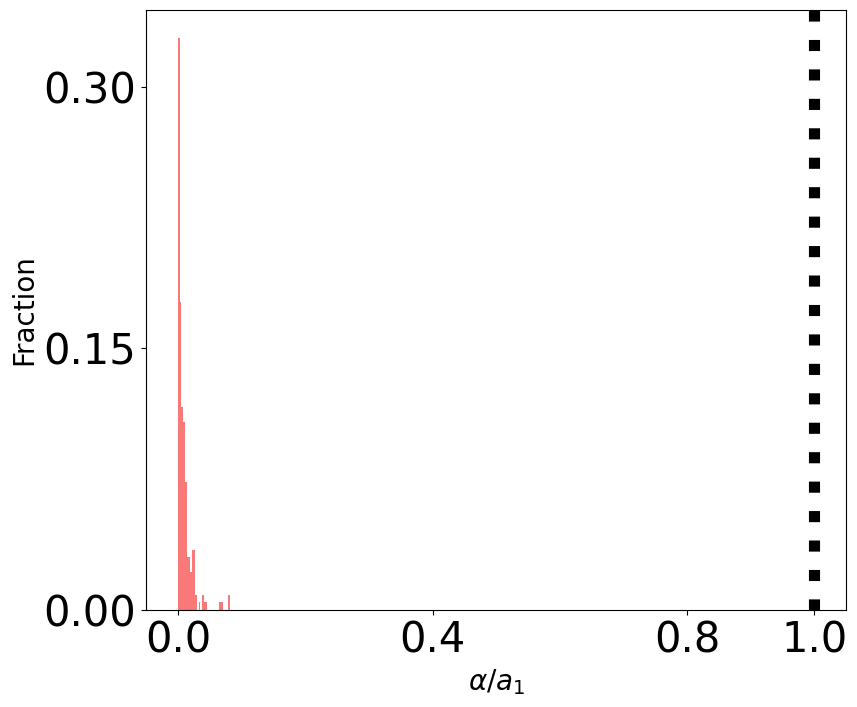

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    a1_list,
    alpha_list,
    bins=30,
    color='#F85858',
    x_label=r'$\alpha/a_1$',
    filename='histogram_alpha_a1.svg'
)

Mean = 0.680207
Standard deviation = 0.136687


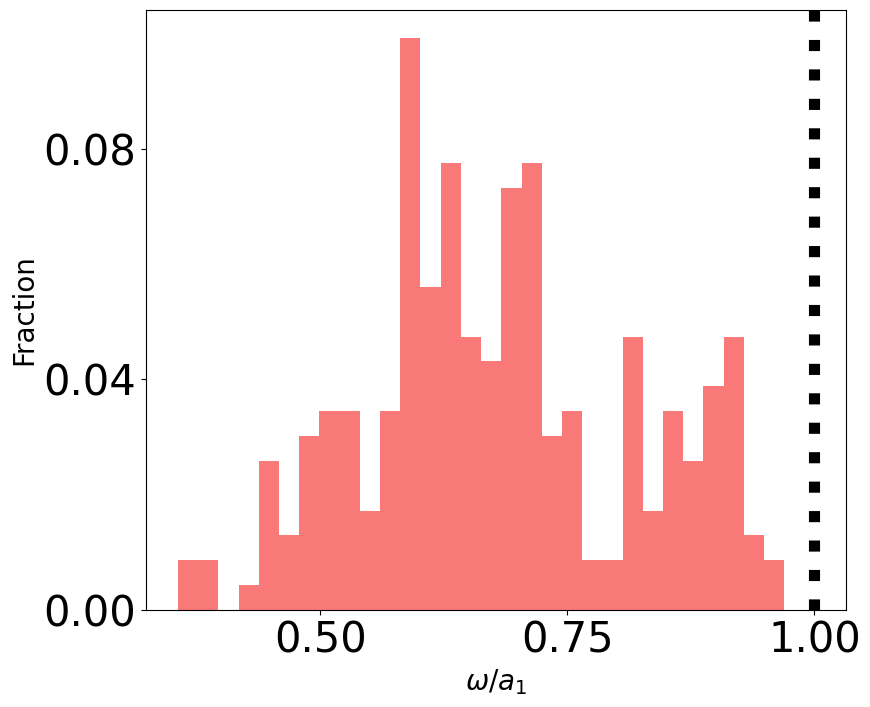

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    a1_list,
    omega_list,
    bins=30,
    color='#F85858',
    x_label=r'$\omega/a_1$',
    filename='histogram_omega_a1.svg'
)

Mean = 0.411075
Standard deviation = 0.151469


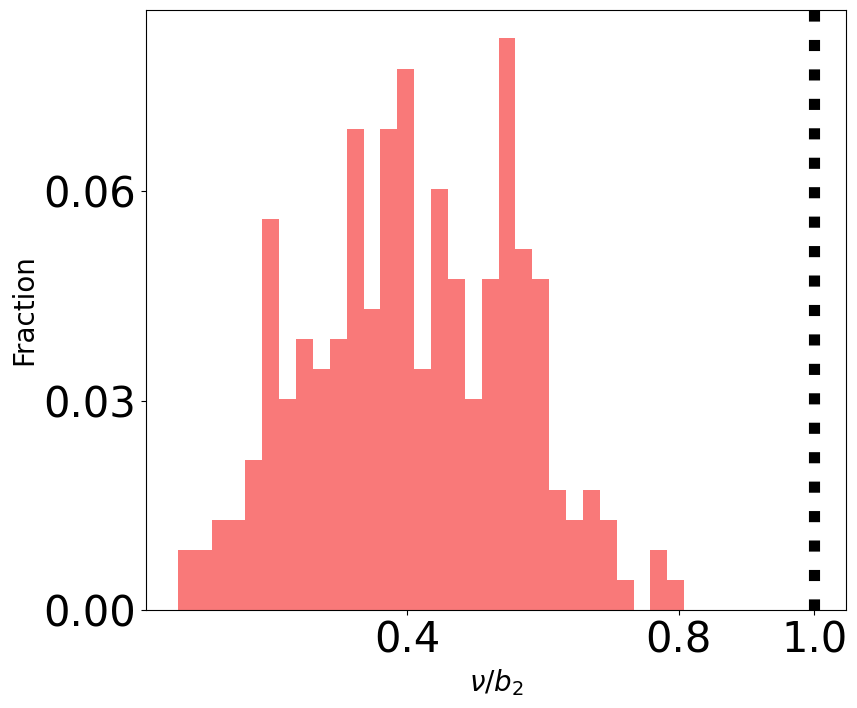

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    b2_list,
    nu_list,
    bins=30,
    color='#F85858',
    x_label=r'$\nu/b_2$',
    filename='histogram_nu_b2.svg'
)

Mean = 0.021681
Standard deviation = 0.034284


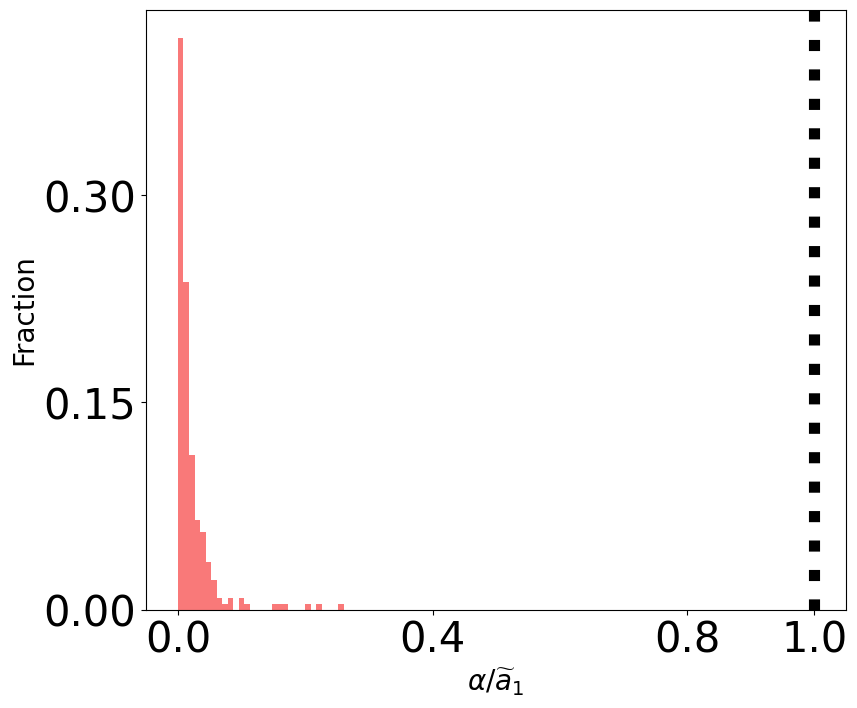

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    a1_tilde_list,
    alpha_list,
    bins=30,
    color='#F85858',
    x_label=r'$\alpha/\widetilde{a}_1$',
    filename='histogram_alpha_a1_tilde.svg'
)

Mean = 0.704217
Standard deviation = 0.105588


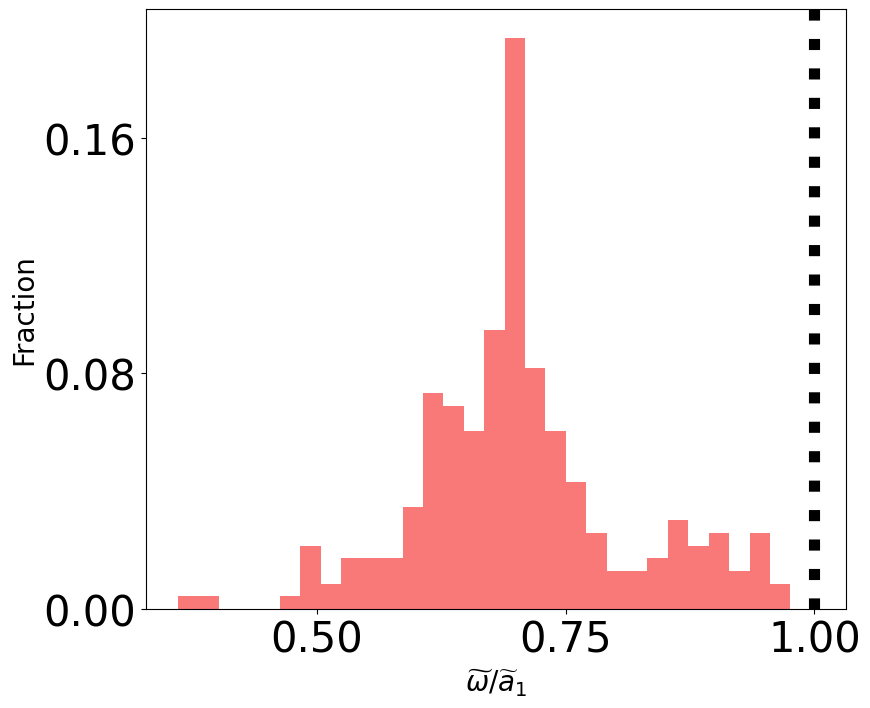

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    a1_tilde_list,
    omega_tilde_list,
    bins=30,
    color='#F85858',
    x_label=r'$\widetilde{\omega}/\widetilde{a}_1$',
    filename='histogram_omega_tilde_a1_tilde.svg'
)

Mean = 0.561216
Standard deviation = 0.160504


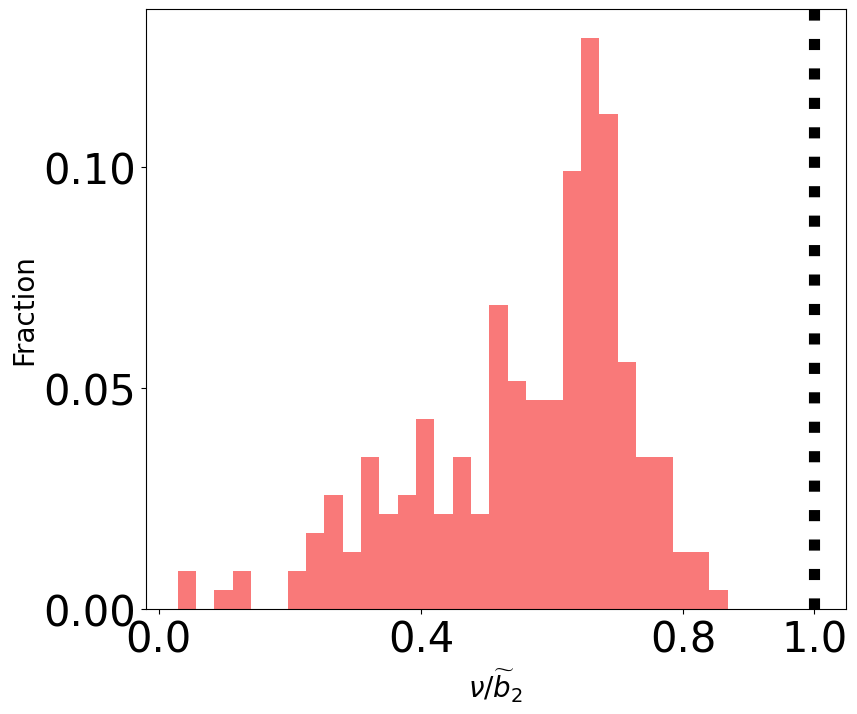

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    b2_tilde_list,
    nu_list,
    bins=30,
    color='#F85858',
    x_label=r'$\nu/\widetilde{b}_2$',
    filename='histogram_nu_b2_tilde.svg'
)

Mean = 0.020076
Standard deviation = 0.026493


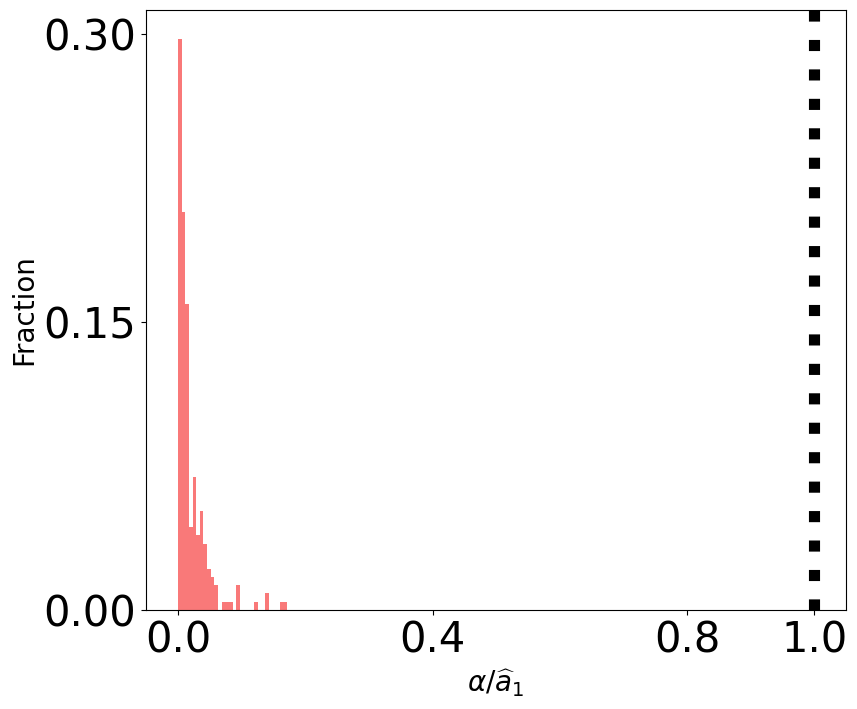

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    a1_hat_list,
    alpha_list,
    bins=30,
    color='#F85858',
    x_label=r'$\alpha/\widehat{a}_1$',
    filename='histogram_alpha_a1_hat.svg'
)

Mean = 0.701750
Standard deviation = 0.097142


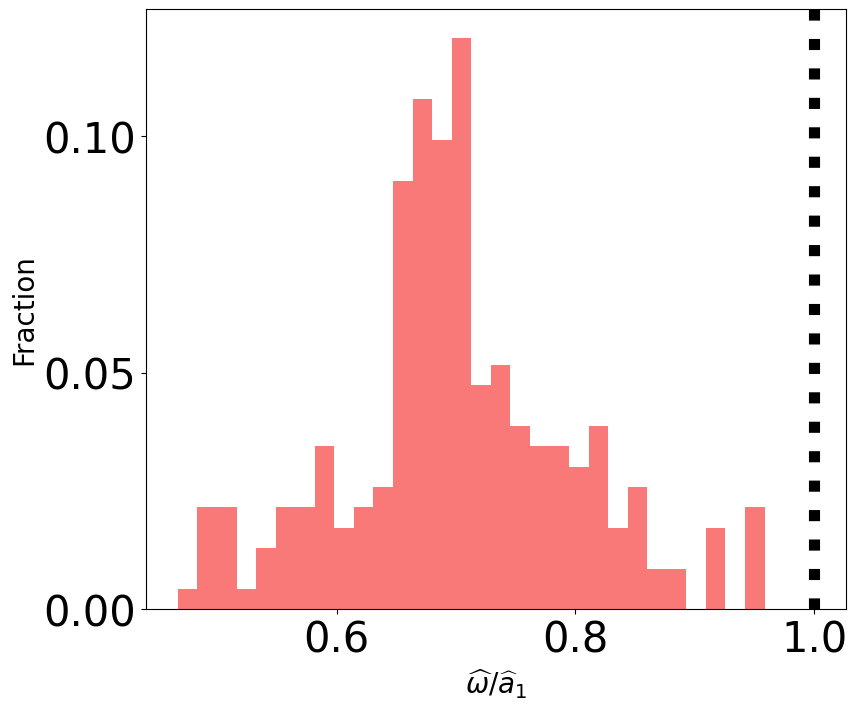

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    a1_hat_list,
    omega_hat_list,
    bins=30,
    color='#F85858',
    x_label=r'$\widehat{\omega}/\widehat{a}_1$',
    filename='histogram_omega_hat_a1_hat.svg'
)

Mean = 0.597425
Standard deviation = 0.076964


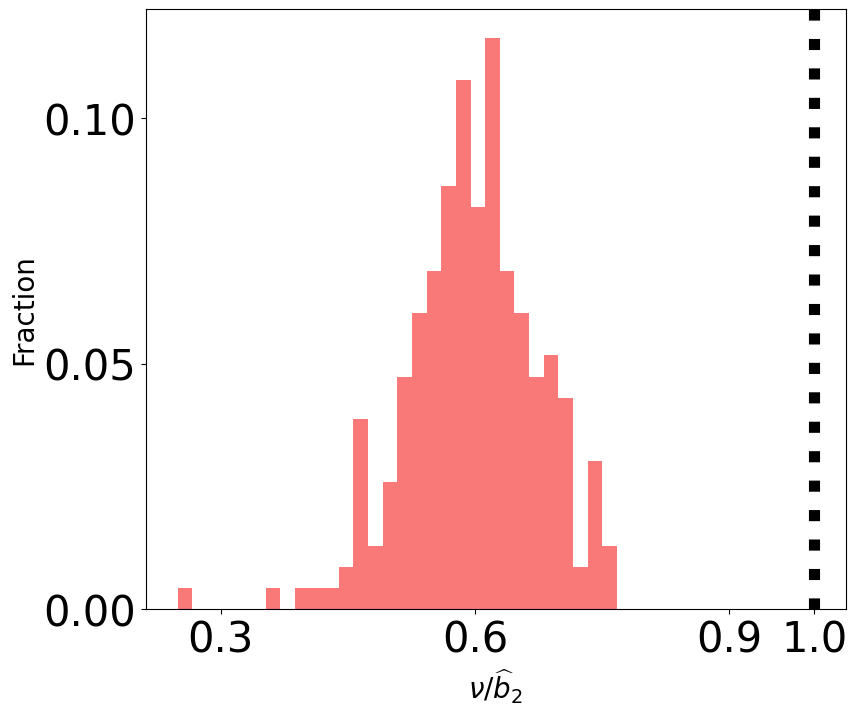

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    b2_hat_list,
    nu_list,
    bins=30,
    color='#F85858',
    x_label=r'$\nu/\widehat{b}_2$',
    filename='histogram_nu_b2_hat.svg'
)

Mean = 0.043507
Standard deviation = 0.059727


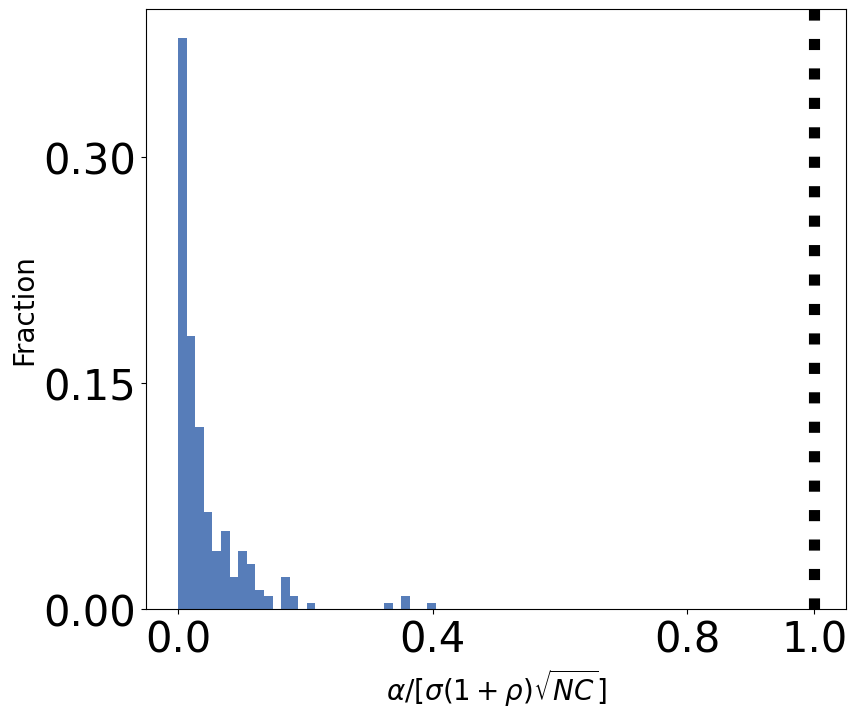

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    alpha_RMT_without_mean_list,
    alpha_list,
    bins=30,
    color='#2D5CA8',
    x_label=r'$\alpha/[\sigma(1+\rho)\sqrt{NC}]$',
    filename='histogram_alpha_RMT_without_mean.svg'
)

Mean = 1.716881
Standard deviation = 0.397143


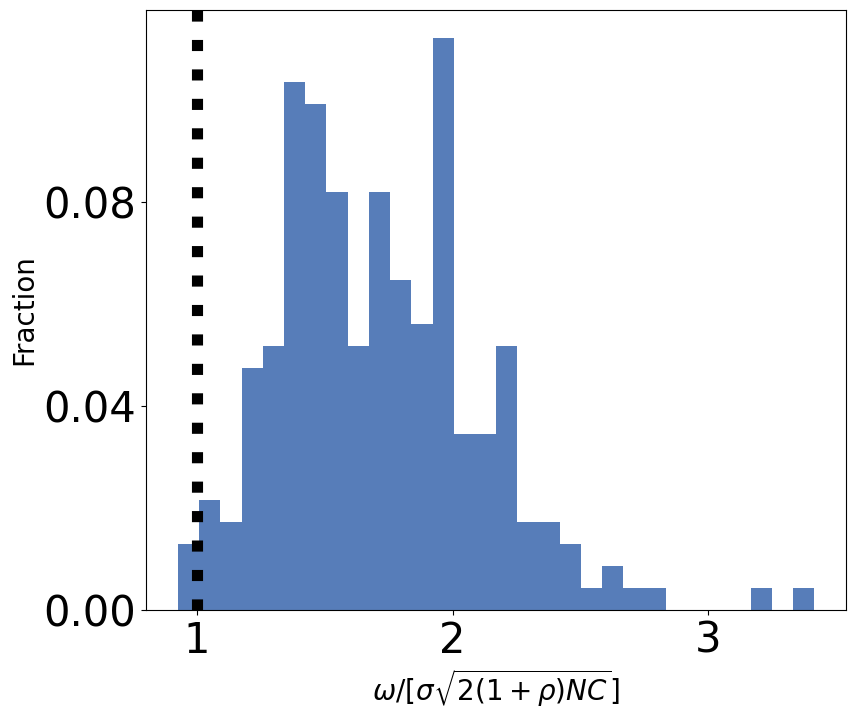

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    omega_RMT_without_mean_list,
    omega_list,
    bins=30,
    color='#2D5CA8',
    x_label=r'$\omega/[\sigma\sqrt{2(1+\rho)NC}]$',
    filename='histogram_omega_RMT_without_mean.svg'
)

Mean = 1.274838
Standard deviation = 0.503430


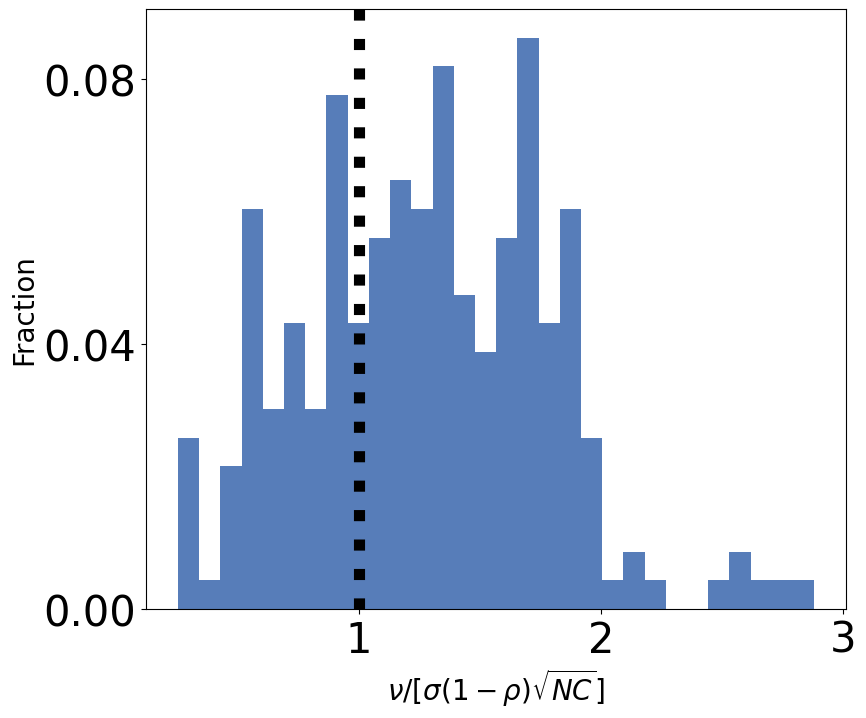

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    nu_RMT_without_mean_list,
    nu_list,
    bins=30,
    color='#2D5CA8',
    x_label=r'$\nu/[\sigma(1-\rho)\sqrt{NC}]$',
    filename='histogram_nu_RMT_without_mean.svg'
)

Mean = 0.039671
Standard deviation = 0.054113


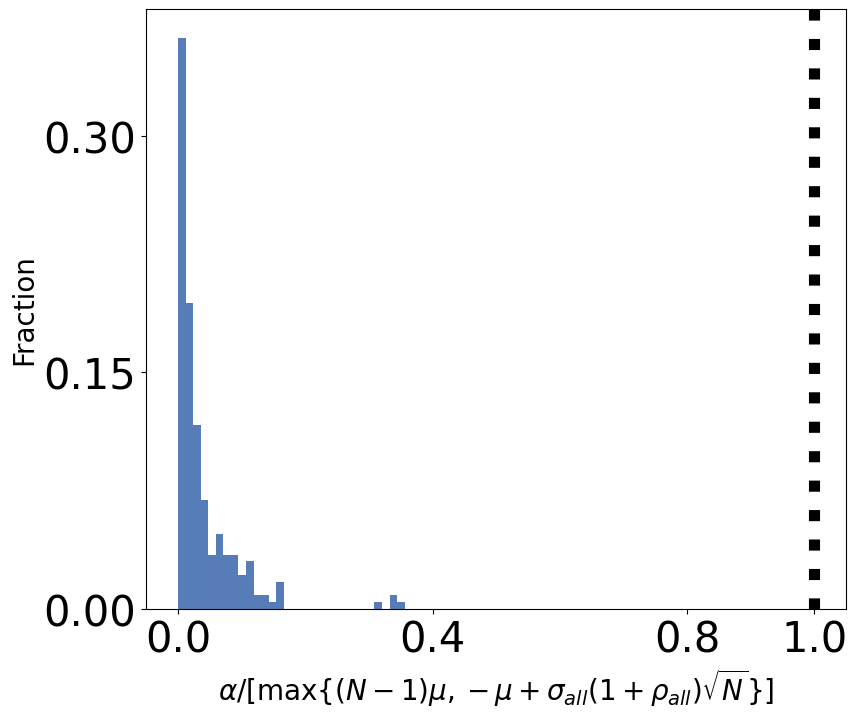

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    alpha_RMT_with_mean_list,
    alpha_list,
    bins=30,
    color='#2D5CA8',
    x_label=r'$\alpha/[\max\{(N-1)\mu, -\mu+\sigma_{all}(1+\rho_{all})\sqrt{N}\}]$',
    filename='histogram_alpha_RMT_with_mean.svg'
)

Mean = 1.651950
Standard deviation = 0.412728


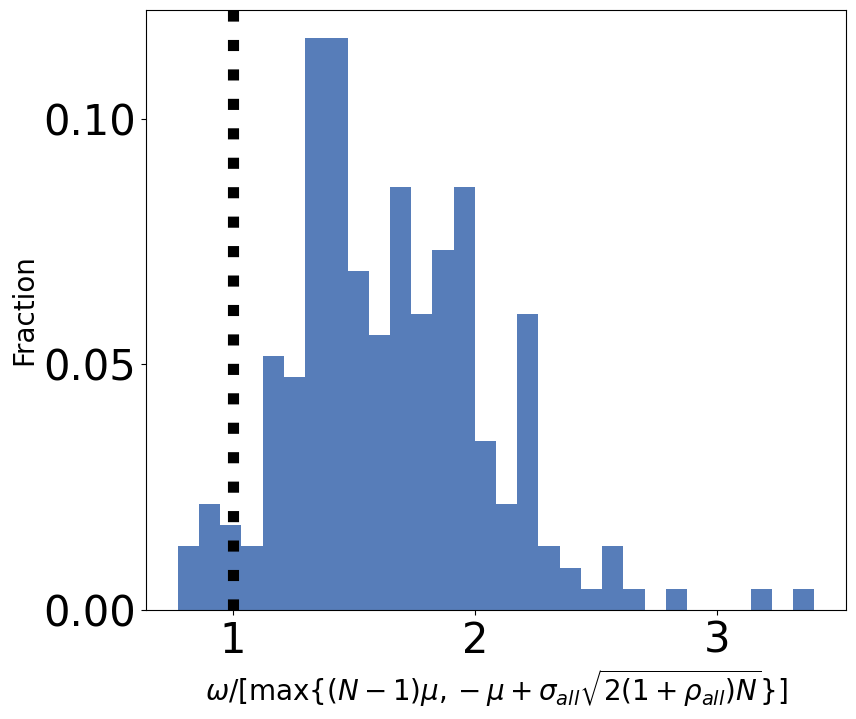

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    omega_RMT_with_mean_list,
    omega_list,
    bins=30,
    color='#2D5CA8',
    x_label=r'$\omega/[\max\{(N-1)\mu, -\mu+\sigma_{all}\sqrt{2(1+\rho_{all})N}\}]$',
    filename='histogram_omega_RMT_with_mean.svg'
)

Mean = 1.285005
Standard deviation = 0.505804


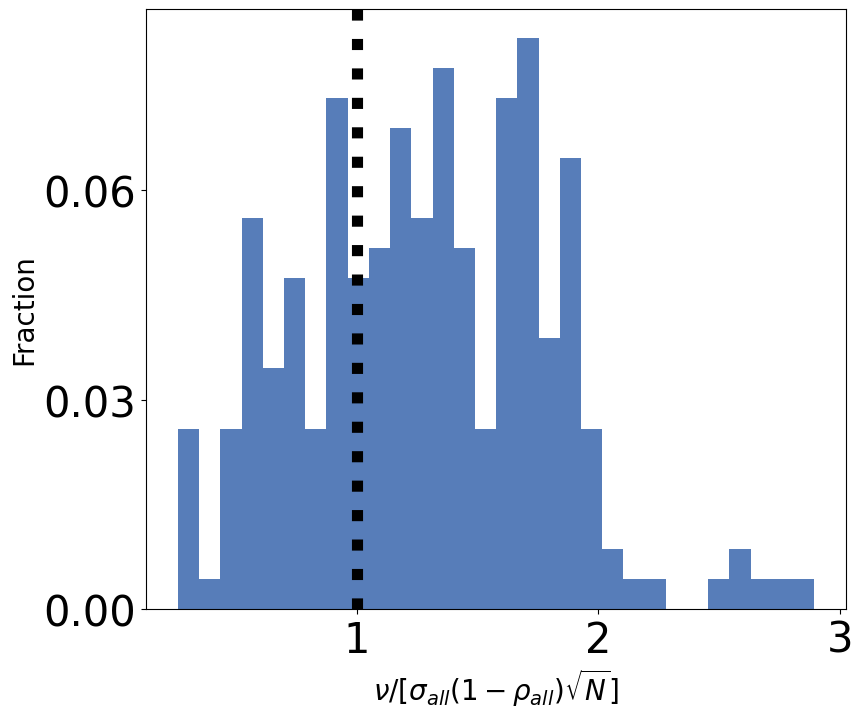

In [ ]:
ratio, mean_ratio, std_ratio = plot_ratio_histogram(
    nu_RMT_with_mean_list,
    nu_list,
    bins=30,
    color='#2D5CA8',
    x_label=r'$\nu/[\sigma_{all}(1-\rho_{all})\sqrt{N}]$',
    filename='histogram_nu_RMT_with_mean.svg'
)

# Draw the network of ecosystems


In [ ]:
def plot_graph_color(i, title, vmin, vmax):
    colormap = plt.cm.cividis
    (X, A) = X_A_list[i]

    M = X @ A
    M_graph = nx.Graph()

    N = A.shape[0]
    M_graph.add_nodes_from(range(N))

    for ii in range(N):
        for jj in range(ii+1, N):
            w = abs(M[ii, jj] + M[jj, ii]) / 2
            if w > 0:
                M_graph.add_edge(ii, jj, weight=w)

    pos = nx.circular_layout(M_graph)

    weights = np.array([
        d['weight']
        for _, _, d in M_graph.edges(data=True)
    ])

    fig, ax = plt.subplots(figsize=(8, 8))

    norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)

    edge_colors = colormap(norm(weights))

    nx.draw_networkx_nodes(
        M_graph,
        pos,
        ax=ax,
        node_color='#2D5CA8',
        node_size=200,
        alpha=1.0
    )

    nx.draw_networkx_edges(
        M_graph,
        pos,
        ax=ax,
        width=1.3,
        edge_color=edge_colors,
        alpha=0.8
    )

    sm = plt.cm.ScalarMappable(
        cmap = colormap,
        norm=norm
    )
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(
        r'$|M_{ij}+M_{ji}|/2$',
        fontsize=20
    )
    cbar.ax.tick_params(labelsize=30)

    ax.set_aspect('equal')
    ax.axis('off')

    plt.savefig(
        title + ".svg",
        format='svg',
        bbox_inches='tight'
    )

    plt.show()

In [ ]:
def get_weights(i):
    X, A = X_A_list[i]
    M = X @ A
    N = A.shape[0]

    weights = []

    for ii in range(N):
        for jj in range(ii+1, N):
            w = abs(M[ii, jj] + M[jj, ii]) / 2
            if w > 0:
                weights.append(w)

    return np.array(weights)

In [ ]:
model_ids = df["model_number"].astype(str).tolist()

idx_small_a1 = model_ids.index("407")  # Tasmanian Seamounts Marine Reserve
idx_large_a1 = model_ids.index("501")  # North Benguela

all_weights = np.concatenate([
    get_weights(idx_small_a1),
    get_weights(idx_large_a1)
])

vmin = all_weights.min()
vmax = all_weights.max()

Plot the network of an ecosystem with small $a_1$.

model name = Tasmanian Seamounts Marine Reserve
model ID = 407
N = 24
alpha = 0.22559644632210352
omega = 7.599382442081398
a1 = 14.947299021392153


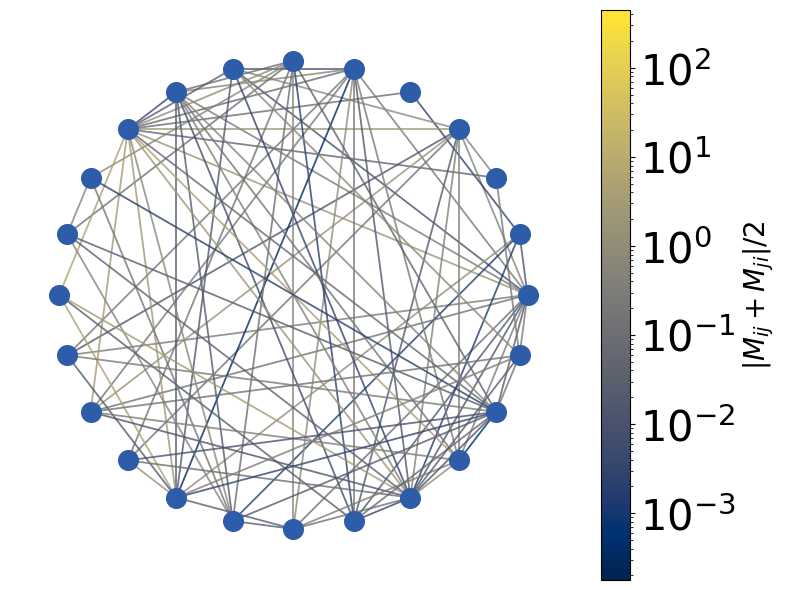

In [ ]:
print("model name =", df["model_name"].iloc[idx_small_a1])
print("model ID =", model_ids[idx_small_a1])
print("N =", N_list[idx_small_a1])
print("alpha =", alpha_list[idx_small_a1])
print("omega =", omega_list[idx_small_a1])
print("a1 =", a1_list[idx_small_a1])

plot_graph_color(idx_small_a1, "graph0", vmin, vmax)

Plot the network of an ecosystem with large $a_1$.

model name = North Benguela
model ID = 501
N = 25
alpha = 3.792505939360363
omega = 454.09629125243873
a1 = 499.11715657720424


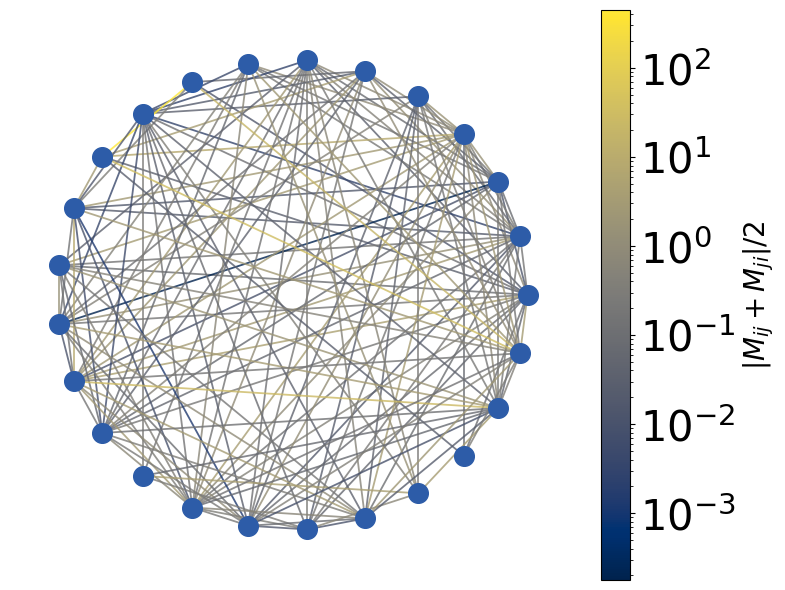

In [ ]:
print("model name =", df["model_name"].iloc[idx_large_a1])
print("model ID =", model_ids[idx_large_a1])
print("N =", N_list[idx_large_a1])
print("alpha =", alpha_list[idx_large_a1])
print("omega =", omega_list[idx_large_a1])
print("a1 =", a1_list[idx_large_a1])

plot_graph_color(idx_large_a1, "graph1", vmin, vmax)